In [39]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

**Part 1: Data Inspection, Cleaning and Preparation**

In [40]:
#read and load raw data set
raw_data = '3.retail_store_sales Assignment 1.csv'
df = pd.read_csv(raw_data)
print(df)

#inspecting data sets
df.columns = df.columns.str.strip()

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
display(df.head())
print("Rows and columns:", df.shape)
df.info()


#Checking data types
display(df.dtypes.rename("data_type").to_frame())

      Transaction ID Customer ID       Category          Item  Price Per Unit  \
0        TXN_6867343     CUST_09     Patisserie   Item_10_PAT            18.5   
1        TXN_3731986     CUST_22  Milk Products  Item_17_MILK            29.0   
2        TXN_9303719     CUST_02       Butchers   Item_12_BUT            21.5   
3        TXN_9458126     CUST_06      Beverages   Item_16_BEV            27.5   
4        TXN_4575373     CUST_05           Food   Item_6_FOOD            12.5   
...              ...         ...            ...           ...             ...   
12570    TXN_9347481     CUST_18     Patisserie   Item_23_PAT            38.0   
12571    TXN_4009414     CUST_03      Beverages    Item_2_BEV             6.5   
12572    TXN_5306010     CUST_11       Butchers    Item_7_BUT            14.0   
12573    TXN_5167298     CUST_04      Furniture    Item_7_FUR            14.0   
12574    TXN_2407494     CUST_23           Food   Item_9_FOOD            17.0   

       Quantity  Total Spen

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,8/4/2024,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,23/7/2023,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,5/10/2022,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,7/5/2022,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2/10/2022,False


Rows and columns: (12575, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  object 
 1   Customer ID       12575 non-null  object 
 2   Category          12575 non-null  object 
 3   Item              11362 non-null  object 
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  object 
 8   Location          12575 non-null  object 
 9   Transaction Date  12575 non-null  object 
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(8)
memory usage: 1.1+ MB


,data_type
Transaction ID,object
Customer ID,object
Category,object
Item,object
Price Per Unit,float64
Quantity,float64
Total Spent,float64
Payment Method,object
Location,object
Transaction Date,object


This dataset contains retail transaction records covering different product categories, prices, quantities purchased, total spending, payment methods, shopping locations, transaction dates, and discount information with 12,575 transaction records and 11 columns.

This step also checkes for datatypes for each columns and finds that records in transaction date has been stored as object rather than date format. TO have a proper data quality, that will be formatted in data cleaning section below.

In [41]:
#defind data cleaning function
def clean_data(raw_data: pd.DataFrame) -> pd.DataFrame:

    # Create a copy to preserve the original dataset
    data = raw_data.copy()

    original_rows = len(data)

    # Standardise column names
    data.columns = data.columns.str.strip()

    # Standardise whitespace in text columns
    text_columns = [
        "Category",
        "Item",
        "Payment Method",
        "Location",
        "Discount Applied"
    ]

    for column in text_columns:
        if column in data.columns:
            data[column] = (
                data[column]
                .astype("string")
                .str.strip()
            )

            # Treat empty strings as missing
            data[column] = data[column].replace(
                {"": pd.NA}
            )

    # Convert numerical columns
    numeric_columns = [
        "Price Per Unit",
        "Quantity",
        "Total Spent"
    ]

    for column in numeric_columns:
        if column in data.columns:
            data[column] = pd.to_numeric(
                data[column],
                errors="coerce"
            )

    # Convert transaction dates
    if "Transaction Date" in data.columns:
        data["Transaction Date"] = pd.to_datetime(
            data["Transaction Date"],
            dayfirst=True,
            errors="coerce"
        )

    # Standardise discount values
    if "Discount Applied" in data.columns:
        discount_map = {
            "true": True,
            "false": False,
            "yes": True,
            "no": False,
            "1": True,
            "0": False
        }

        data["Discount Applied"] = (
            data["Discount Applied"]
            .astype("string")
            .str.lower()
            .map(discount_map)
            .astype("boolean")
        )

    # Remove exact duplicates after text standardisation
    data = data.drop_duplicates().copy()

    # Recalculate missing totals when both inputs are available
    required_columns = [
        "Total Spent",
        "Price Per Unit",
        "Quantity"
    ]

    if all(col in data.columns for col in required_columns):

        can_calculate_total = (
            data["Total Spent"].isna()
            & data["Price Per Unit"].notna()
            & data["Quantity"].notna()
        )

        data.loc[can_calculate_total, "Total Spent"] = (
            data.loc[can_calculate_total, "Price Per Unit"]
            * data.loc[can_calculate_total, "Quantity"]
        )

    # Flag potentially invalid prices
    if "Price Per Unit" in data.columns:
        data["Potential Invalid Price"] = (
            data["Price Per Unit"].notna()
            & data["Price Per Unit"].le(0)
        )

    # Flag potentially invalid quantities
    if "Quantity" in data.columns:
        data["Potential Invalid Quantity"] = (
            data["Quantity"].notna()
            & data["Quantity"].le(0)
        )

    # Check transaction-total consistency
    required_columns = [
        "Price Per Unit",
        "Quantity",
        "Total Spent"
    ]

    if all(col in data.columns for col in required_columns):

        comparable = (
            data["Price Per Unit"].notna()
            & data["Quantity"].notna()
            & data["Total Spent"].notna()
        )

        calculated_total = (
            data["Price Per Unit"] * data["Quantity"]
        )

        matches = np.isclose(
            data["Total Spent"].fillna(0),
            calculated_total.fillna(0),
            rtol=0.01,
            atol=0.01
        )

        data["Potential Total Mismatch"] = (
            comparable & ~matches
        )

    # Print cleaning summary
    print("DATA CLEANING SUMMARY")
    print("-" * 35)
    print(f"Rows before cleaning: {original_rows:,}")
    print(
        f"Exact duplicate rows removed: "
        f"{original_rows - len(data):,}"
    )
    print(f"Rows after cleaning: {len(data):,}")

    if "Potential Total Mismatch" in data.columns:
        print(
            "Potential total mismatches:",
            int(data["Potential Total Mismatch"].sum())
        )

    return data


# Run the cleaning function
cleaned_data = clean_data(df)

# Display the cleaned dataset
display(cleaned_data.head())

DATA CLEANING SUMMARY
-----------------------------------
Rows before cleaning: 12,575
Exact duplicate rows removed: 0
Rows after cleaning: 12,575
Potential total mismatches: 0


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied,Potential Invalid Price,Potential Invalid Quantity,Potential Total Mismatch
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True,False,False,False
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True,False,False,False
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False,False,False,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,<NA>,False,False,False
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False,False,False,False


Preparing the retail sales data improves consistency across product descriptions, numerical values, transaction dates, and discount information. Missing transaction totals may be calculated when both unit price and quantity are available, provided the calculation reflects the dataset's transaction structure.

In [42]:
#Check duplicate row and transaction IDs
# Check exact duplicate rows
duplicate_count = cleaned_data.duplicated().sum()

print("Exact duplicate rows remaining:", duplicate_count)

if duplicate_count > 0:
    display(
        cleaned_data[
            cleaned_data.duplicated(keep=False)
        ]
    )
else:
    print("There are no duplicate rows.")


# Check duplicate transaction IDs
duplicate_ids = cleaned_data[
    cleaned_data["Transaction ID"].duplicated(keep=False)
]

print(
    "\nRows with repeated transaction IDs:",
    len(duplicate_ids)
)

if not duplicate_ids.empty:
    display(duplicate_ids.head(20))
else:
    print("There are no repeated transaction IDs.")

Exact duplicate rows remaining: 0
There are no duplicate rows.

Rows with repeated transaction IDs: 0
There are no repeated transaction IDs.


Duplicate records can cause sales totals and transaction counts to be overstated. The initial inspection found no exact duplicate rows, suggesting that the dataset does not contain identical records that need to be removed.

In [43]:

# Calculate missing counts and percentages
def check_missing_values(data):
    missing_summary = pd.DataFrame({
        "Missing Count": data.isna().sum(),
        "Missing Percentage": (
            data.isna().sum() / len(data) * 100
        ).round(2)
    })

    missing_summary = missing_summary.sort_values(
        "Missing Percentage",
        ascending=False
    )

    print("Missing Value Summary")
    display(missing_summary)

    return missing_summary


missing_summary = check_missing_values(cleaned_data)




Missing Value Summary


,Missing Count,Missing Percentage
Discount Applied,4199,33.39
Item,1213,9.65
Price Per Unit,609,4.84
Quantity,604,4.80
Total Spent,604,4.80
Transaction ID,0,0.00
Category,0,0.00
Customer ID,0,0.00
Location,0,0.00
Payment Method,0,0.00




The initial inspection identifies missing information in several fields, particularly `Discount Applied`, `Item`, `Price Per Unit`, `Quantity`, and `Total Spent`. Missing discount information is especially noticeable, affecting approximately 33.39% of the records. These gaps may limit the analysis of discount usage and reduce the number of complete records available for sales calculations.

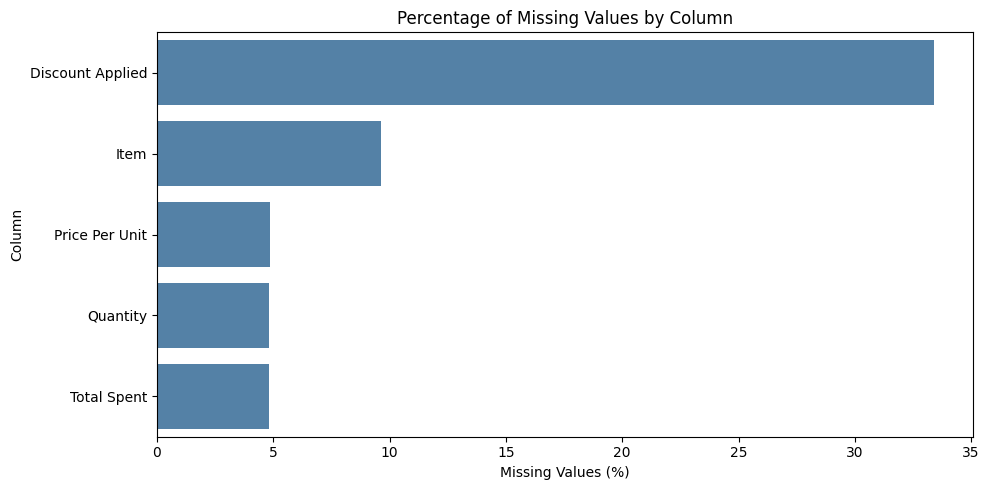

In [44]:
#visualize the missing values counts and percentage to verify which column has most
def plot_missing_values(data):
    """Plot the percentage of missing values per column."""

    missing_percent = (
        data.isna().mean() * 100
    ).sort_values(ascending=False)

    missing_percent = missing_percent[missing_percent > 0]

    if missing_percent.empty:
        print("There are no missing values.")
        return

    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=missing_percent.values,
        y=missing_percent.index,
        color="steelblue"
    )

    plt.title("Percentage of Missing Values by Column")
    plt.xlabel("Missing Values (%)")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()


plot_missing_values(cleaned_data)

According to the bar chart, there are lots of missing values in Discount Applied column and had been sorted out in above section.

**Part 2: Descriptive statistics**

In [45]:
# Select numerical columns for descriptive statistics
numeric_data = cleaned_data[
    ["Price Per Unit", "Quantity", "Total Spent"]
]

# Calculate descriptive statistics
display(numeric_data.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Price Per Unit,11966.0,23.37,10.74,5.0,14.0,23.0,33.5,41.0
Quantity,11971.0,5.54,2.86,1.0,3.0,6.0,8.0,10.0
Total Spent,11971.0,129.65,94.75,5.0,51.0,108.5,192.0,410.0


Descriptive statistics provide an overview of product prices, quantities purchased, and total transaction spending. The average and median spending help describe typical transaction values, while the standard deviation indicates how much spending varies across records.



In [46]:
# Minimum and maximum values
numeric_columns = [
    "Price Per Unit",
    "Quantity",
    "Total Spent"
]
print("Minimum and Maximum Values")
display(cleaned_data[numeric_columns].agg(["min", "max"]).T)


# Check non-positive prices and quantities
invalid_price = (
    cleaned_data["Price Per Unit"].notna()
    & cleaned_data["Price Per Unit"].le(0)
)

invalid_quantity = (
    cleaned_data["Quantity"].notna()
    & cleaned_data["Quantity"].le(0)
)

# Negative totals may represent refunds, so investigate them
negative_total = cleaned_data["Total Spent"].lt(0).fillna(False)

print("Non-positive prices:", invalid_price.sum())
print("Non-positive quantities:", invalid_quantity.sum())
print("Negative transaction totals:", negative_total.sum())

# Display records that need investigation
invalid_records = cleaned_data[
    invalid_price | invalid_quantity | negative_total
]

display(invalid_records.head(20))

#Check transactation date to identify suspicious values
print(
    "Earliest transaction:",
    cleaned_data["Transaction Date"].min()
)

print(
    "Latest transaction:",
    cleaned_data["Transaction Date"].max()
)

Minimum and Maximum Values


,min,max
Price Per Unit,5.0,41.0
Quantity,1.0,10.0
Total Spent,5.0,410.0


Non-positive prices: 0
Non-positive quantities: 0
Negative transaction totals: 0


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied,Potential Invalid Price,Potential Invalid Quantity,Potential Total Mismatch


Earliest transaction: 2022-01-01 00:00:00
Latest transaction: 2025-01-18 00:00:00


In [47]:
#Examine category frequencies
def display_category_counts(data, column):
    """Display the frequency of each category."""

    print(f"\nFrequency counts for {column}:")

    counts = data[column].value_counts(dropna=False)

    display(counts.to_frame(name="Count"))


#Examine important categorical columns
for column in [
    "Category",
    "Item",
    "Payment Method",
    "Location"
]:
    if column in cleaned_data.columns:
        display_category_counts(cleaned_data, column)



Frequency counts for Category:


,Count
Category,
Electric household essentials,1591
Furniture,1591
Food,1588
Milk Products,1584
Butchers,1568
Beverages,1567
Computers and electric accessories,1558
Patisserie,1528



Frequency counts for Item:


,Count
Item,
<NA>,1213
Item_2_BEV,126
Item_25_FUR,113
Item_11_FUR,110
Item_16_MILK,109
...,...
Item_5_BEV,7
Item_13_BEV,7
Item_13_FUR,7



Frequency counts for Payment Method:


,Count
Payment Method,
Cash,4310
Digital Wallet,4144
Credit Card,4121



Frequency counts for Location:


,Count
Location,
Online,6354
In-store,6221


In [48]:
# Summarise sales by category
sales_by_category = cleaned_data.groupby("Category").agg(
    Total_Sales=("Total Spent", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Number_of_Transactions=("Transaction ID", "nunique"),
    Average_Sales=("Total Spent", "mean")
).round(2)

# Sort categories by total sales, highest first
sales_by_category = sales_by_category.sort_values(
    by="Total_Sales",
    ascending=False
)

display(sales_by_category)

,Total_Sales,Total_Quantity,Number_of_Transactions,Average_Sales
Category,,,,
Butchers,208118.0,8206.0,1568,139.12
Electric household essentials,203813.5,8309.0,1591,134.44
Beverages,197047.5,8358.0,1567,131.72
Furniture,195310.0,8462.0,1591,128.07
Food,194812.0,8387.0,1588,129.27
Computers and electric accessories,190692.5,8272.0,1558,129.11
Patisserie,182165.5,7943.0,1528,126.42
Milk Products,180112.0,8339.0,1584,119.04


When breaking down the sales summary, the butchers category has the highest sales compare to others categories such as beverages, food, and so on.

In [49]:
#Check potential outliers using IQR
def detect_outliers_iqr(data, column):
    """Flag potential outliers using the interquartile range."""

    values = data[column].dropna()

    if values.empty:
        print(f"No available values for {column}.")
        return pd.Series(False, index=data.index)

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (data[column] < lower_bound)
        | (data[column] > upper_bound)
    ).fillna(False)

    print(f"\nOutlier analysis for {column}")
    print(f"Q1: {q1:.2f}")
    print(f"Q3: {q3:.2f}")
    print(f"IQR: {iqr:.2f}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Potential outliers: {outlier_mask.sum()}")

    return outlier_mask


# Run outlier detection
price_outliers = detect_outliers_iqr(
    cleaned_data, "Price Per Unit"
)

quantity_outliers = detect_outliers_iqr(
    cleaned_data, "Quantity"
)

total_outliers = detect_outliers_iqr(
    cleaned_data, "Total Spent"
)


Outlier analysis for Price Per Unit
Q1: 14.00
Q3: 33.50
IQR: 19.50
Lower bound: -15.25
Upper bound: 62.75
Potential outliers: 0

Outlier analysis for Quantity
Q1: 3.00
Q3: 8.00
IQR: 5.00
Lower bound: -4.50
Upper bound: 15.50
Potential outliers: 0

Outlier analysis for Total Spent
Q1: 51.00
Q3: 192.00
IQR: 141.00
Lower bound: -160.50
Upper bound: 403.50
Potential outliers: 60


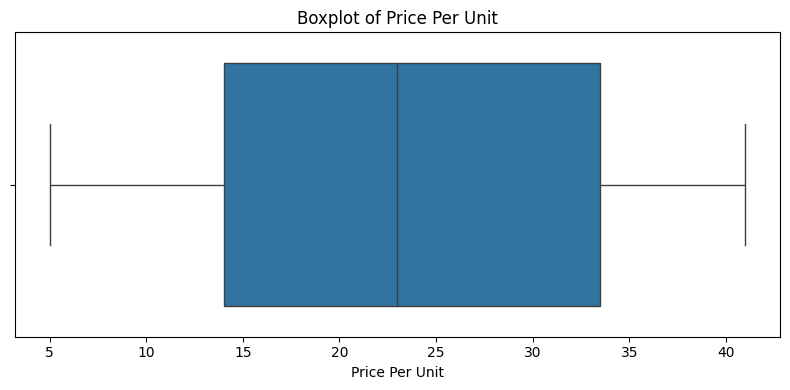

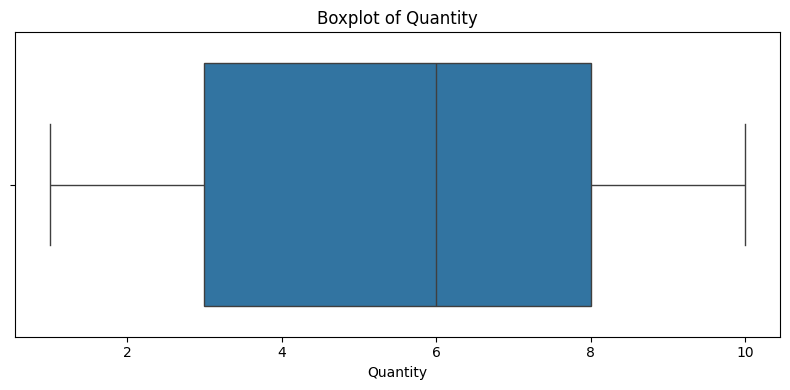

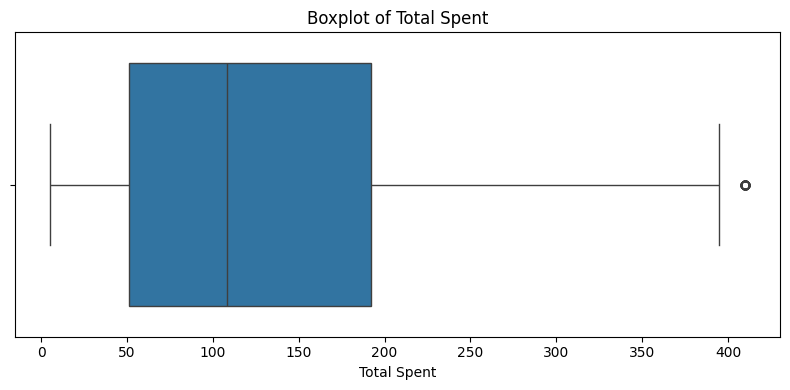

In [50]:
#Visualize Outliers using boxplot
def plot_price_boxplot(data):
    """Plot a boxplot of unit prices."""

    plt.figure(figsize=(8, 4))
    sns.boxplot(x=data["Price Per Unit"])
    plt.title("Boxplot of Price Per Unit")
    plt.xlabel("Price Per Unit")
    plt.tight_layout()
    plt.show()


def plot_quantity_boxplot(data):
    """Plot a boxplot of quantities."""

    plt.figure(figsize=(8, 4))
    sns.boxplot(x=data["Quantity"])
    plt.title("Boxplot of Quantity")
    plt.xlabel("Quantity")
    plt.tight_layout()
    plt.show()


def plot_total_spent_boxplot(data):
    """Plot a boxplot of transaction totals."""

    plt.figure(figsize=(8, 4))
    sns.boxplot(x=data["Total Spent"])
    plt.title("Boxplot of Total Spent")
    plt.xlabel("Total Spent")
    plt.tight_layout()
    plt.show()


# Generate separate plots
plot_price_boxplot(cleaned_data)
plot_quantity_boxplot(cleaned_data)
plot_total_spent_boxplot(cleaned_data)

The boxplot shows the distribution of Total Spent and identifies outliers using the Interquartile Range (IQR) method. An evaluation of the Total Spent distribution reveals a positively skewed dataset bounded between an lower limit of approximately 5 and an upper boundary whisker at 395. The interquartile range (IQR) spans from 50 (Q1) to 190 (Q3), with a central median of 110.   

In [51]:
display(
    cleaned_data.loc[
        total_outliers,
        [
            "Transaction ID",
            "Category",
            "Price Per Unit",
            "Quantity",
            "Total Spent"
        ]
    ].sort_values("Total Spent", ascending=False)
)

,Transaction ID,Category,Price Per Unit,Quantity,Total Spent
27,TXN_1599706,Furniture,41.0,10.0,410.0
133,TXN_2953434,Furniture,41.0,10.0,410.0
339,TXN_4374445,Food,41.0,10.0,410.0
869,TXN_1814138,Beverages,41.0,10.0,410.0
1060,TXN_3710081,Furniture,41.0,10.0,410.0
1088,TXN_1273334,Beverages,41.0,10.0,410.0
1468,TXN_1938135,Butchers,41.0,10.0,410.0
1505,TXN_8520397,Electric household essentials,41.0,10.0,410.0
1568,TXN_8048041,Butchers,41.0,10.0,410.0
1950,TXN_1860120,Furniture,41.0,10.0,410.0


In [52]:
#Check final dataset after data preprocessing
print("FINAL DATASET SUMMARY")
print("-" * 40)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", cleaned_data.shape)

print("\nData types:")
display(cleaned_data.dtypes.rename("Data Type").to_frame())

print("\nRemaining missing values:")
display(
    cleaned_data.isna().sum().rename(
        "Missing Count"
    ).to_frame()
)

print("\nDuplicate rows:", cleaned_data.duplicated().sum())

print(
    "Duplicate transaction IDs:",
    cleaned_data["Transaction ID"].duplicated().sum()
)

print("\nFinal descriptive statistics:")
display(
    cleaned_data[
        ["Price Per Unit", "Quantity", "Total Spent"]
    ].describe().round(2)
)

FINAL DATASET SUMMARY
----------------------------------------
Original dataset shape: (12575, 11)
Cleaned dataset shape: (12575, 14)

Data types:


,Data Type
Transaction ID,object
Customer ID,object
Category,string[python]
Item,string[python]
Price Per Unit,float64
Quantity,float64
Total Spent,float64
Payment Method,string[python]
Location,string[python]
Transaction Date,datetime64[ns]



Remaining missing values:


,Missing Count
Transaction ID,0
Customer ID,0
Category,0
Item,1213
Price Per Unit,609
Quantity,604
Total Spent,604
Payment Method,0
Location,0
Transaction Date,0



Duplicate rows: 0
Duplicate transaction IDs: 0

Final descriptive statistics:


,Price Per Unit,Quantity,Total Spent
count,11966.00,11971.00,11971.00
mean,23.37,5.54,129.65
std,10.74,2.86,94.75
min,5.00,1.00,5.00
25%,14.00,3.00,51.00
50%,23.00,6.00,108.50
75%,33.50,8.00,192.00
max,41.00,10.00,410.00


In [53]:
#Save cleaned data set
cleaned_data.to_csv(
    "retail_store_sales_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


**Part 3: Correlation Analysis**

In [54]:

# Correlation analysis: Numerical table
def correlation_table(data):
    """Display correlations between numerical sales variables."""

    # Select numerical variables
    numeric_data = data[
        ["Price Per Unit", "Quantity", "Total Spent"]
    ]

    # Calculate correlation coefficients
    correlation = numeric_data.corr()

    # Display the numerical correlation table
    print("Correlation Between Sales Variables:")
    display(correlation.round(2))


correlation_table(cleaned_data)


Correlation Between Sales Variables:


,Price Per Unit,Quantity,Total Spent
Price Per Unit,1.00,0.01,0.63
Quantity,0.01,1.00,0.71
Total Spent,0.63,0.71,1.00




The correlation matrix reveals key relationships among the three numerical sales metrics. Notably, **Price Per Unit** and **Quantity** exhibit virtually no linear correlation ($r = 0.01$), indicating that transaction volume is independent of individual item pricing. In contrast, both variables demonstrate strong positive relationships with **Total Spent**. **Quantity** serves as the primary driver of expenditure with a strong correlation of $r = 0.71$, closely followed by **Price Per Unit** at $r = 0.63$. These results indicate that higher total spending is driven conjointly by larger order quantities and higher unit prices, with quantity having a slightly stronger impact overall.

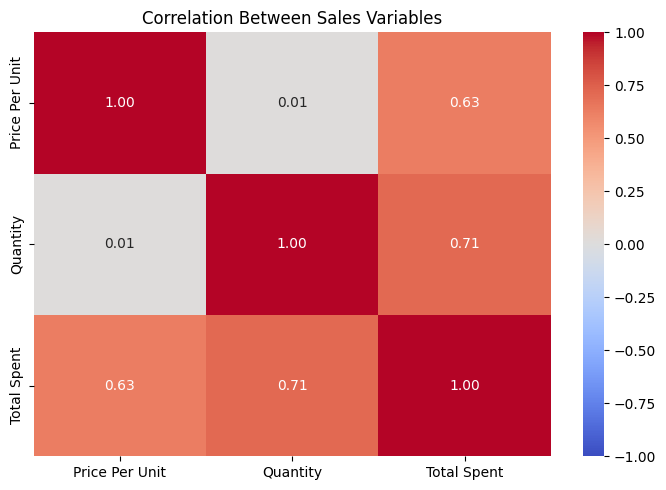

In [55]:
#correlation analysis using heatmap
def plot_correlation(data):
    """Plot correlations between numerical sales variables."""

    numeric_data = data[
        ["Price Per Unit", "Quantity", "Total Spent"]
    ]

    correlation = numeric_data.corr()

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        fmt=".2f"
    )

    plt.title("Correlation Between Sales Variables")
    plt.tight_layout()
    plt.show()


plot_correlation(cleaned_data)

**Part 4: Visualizations**

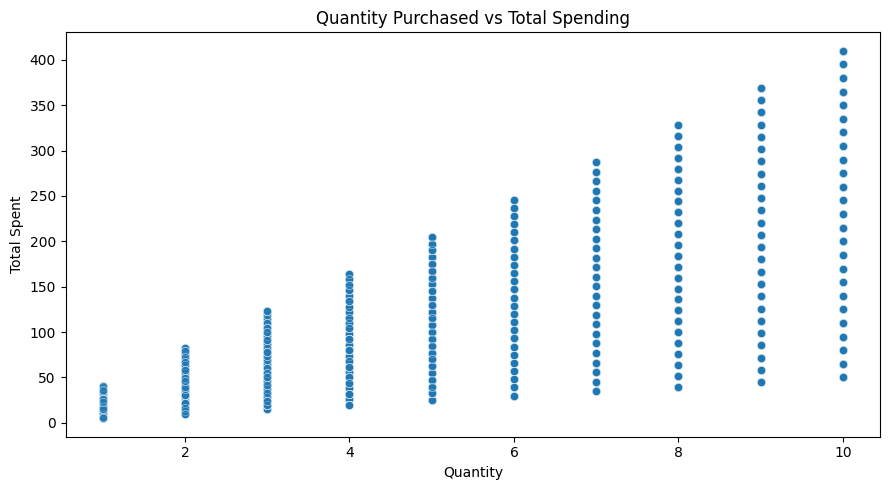

In [56]:
#Relational plot
def plot_quantity_vs_spending(data):
    """Show the relationship between quantity and total spending."""

    plot_data = data.dropna(
        subset=["Quantity", "Total Spent"]
    )

    plt.figure(figsize=(9, 5))
    sns.scatterplot(
        data=plot_data,
        x="Quantity",
        y="Total Spent",
        alpha=0.6
    )

    plt.title("Quantity Purchased vs Total Spending")
    plt.xlabel("Quantity")
    plt.ylabel("Total Spent")
    plt.tight_layout()
    plt.show()


plot_quantity_vs_spending(cleaned_data)

**Relational Analysis: Quantity Purchased vs. Total Spending**

The scatter plot illustrates a clear **positive linear trend** between the unit **Quantity** (discrete values from 1 to 10) and **Total Spent**. As the quantity purchased increases, both the lower and upper bounds of total spending rise accordingly. Additionally, the plot highlights **increasing variance (heteroscedasticity)**: at lower quantities, total spent remains tightly clustered below 125, whereas at higher quantities, expenditure spreads widely across a broader price spectrum (reaching over 400). This pattern demonstrates that purchasing larger quantities amplifies the impact of item unit price on the final total cost.

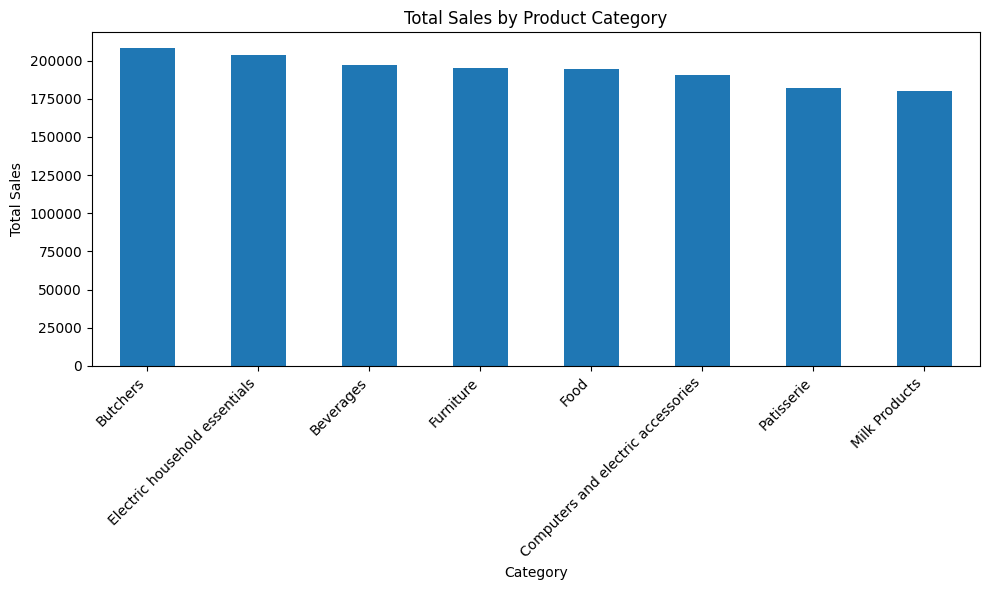

In [57]:
#Categorical plot — sales by category
def plot_sales_by_category(data):
    """Compare total sales across product categories."""

    sales = (
        data.groupby("Category")["Total Spent"]
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 6))
    sales.plot(kind="bar")

    plt.title("Total Sales by Product Category")
    plt.xlabel("Category")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


plot_sales_by_category(cleaned_data)

**Categorical Analysis: Total Sales by Product Category**

The bar chart illustrates the revenue distribution across eight distinct product categories, revealing a well-balanced sales spread with minimal variation between high and low performers. **Butchers** leads total revenue at approximately **208,000**, closely followed by **Electric household essentials** at around **203,000**. Mid-tier categories—including **Beverages**, **Furniture**, **Food**, and **Computers and electric accessories**—maintain steady revenue between **190,000** and **197,000**. **Patisserie** (~182,000) and **Milk Products** (~180,000) round out the lower end of the spectrum. Overall, sales are evenly distributed across all product lines, with less than a 15% disparity separating the highest-performing category from the lowest.

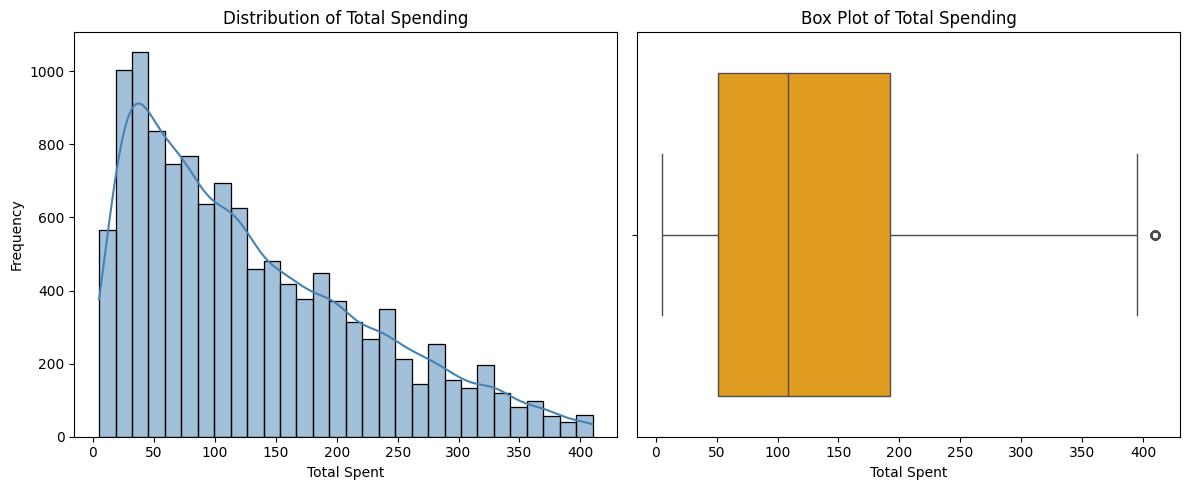

In [58]:
def plot_spending_distribution(data):
    """Show the distribution and potential outliers in total spending."""

    spending = data["Total Spent"].dropna()

    if spending.empty:
        print("There are no available spending values.")
        return

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sns.histplot(
        spending,
        bins=30,
        kde=True,
        color="steelblue",
        ax=axes[0]
    )
    axes[0].set_title("Distribution of Total Spending")
    axes[0].set_xlabel("Total Spent")
    axes[0].set_ylabel("Frequency")

    sns.boxplot(
        x=spending,
        color="orange",
        ax=axes[1]
    )
    axes[1].set_title("Box Plot of Total Spending")
    axes[1].set_xlabel("Total Spent")

    plt.tight_layout()
    plt.show()


plot_spending_distribution(cleaned_data)

**Distribution Analysis: Total Spending**

The combined histogram and boxplot illustrate a right-skewed (positively skewed) distribution for **Total Spent**, indicating that the majority of customer transactions consist of smaller purchasing amounts. The histogram peaks sharply at lower values—specifically between **30** and **50**—where transaction frequency reaches over **1,000** instances, before steadily declining as spending amounts increase. The accompanying boxplot reinforces this behavior: 50% of all transactions (the Interquartile Range) fall between approximately **50** (Q1) and **190** (Q3), with a median expenditure centered around **110**. Furthermore, a solitary outlier is detected at approximately **410**, positioned beyond the upper whisker boundary near **395**, highlighting an exceptionally high single transaction relative to the standard customer spending profile.

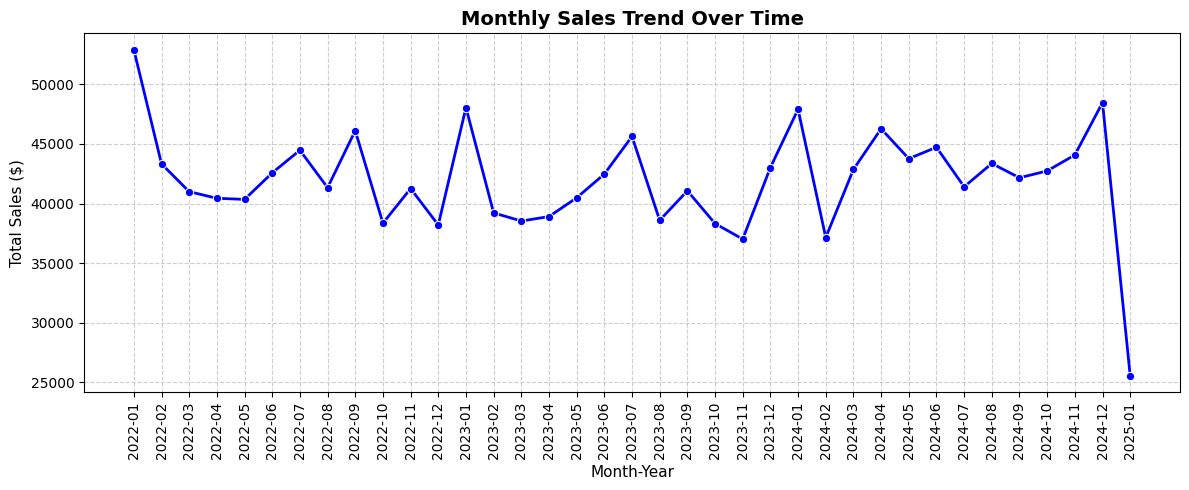

In [59]:
#Monthly sales trend over time
def plot_monthly_sales_trend(data):
    """Show the monthly sales trend over time."""

    # Drop missing values for required columns following your code style
    plot_data = data.dropna(subset=["Transaction Date", "Total Spent", "Category"]).copy()

    # Parse dates and extract Month-Year period
    plot_data['Parsed_Date'] = pd.to_datetime(plot_data['Transaction Date'], dayfirst=True)
    plot_data['Month_Year'] = plot_data['Parsed_Date'].dt.to_period('M')

    # Group by month and sum total sales
    monthly_sales = plot_data.groupby('Month_Year')['Total Spent'].sum().reset_index()
    monthly_sales['Month_Year'] = monthly_sales['Month_Year'].astype(str)

    # Plot line chart
    plt.figure(figsize=(12, 5))
    sns.lineplot(
        data=monthly_sales,
        x='Month_Year',
        y='Total Spent',
        marker='o',
        linewidth=2,
        color='b'
    )
    plt.title("Monthly Sales Trend Over Time", fontsize=14, fontweight='bold')
    plt.xlabel("Month-Year", fontsize=11)
    plt.ylabel("Total Sales ($)", fontsize=11)
    plt.xticks(rotation=90)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()


# Call the function using your cleaned dataset
plot_monthly_sales_trend(cleaned_data)

**Trend Analysis: Monthly Sales Over Time**

The line chart tracks **Monthly Sales** from **January 2022 to January 2025**, revealing consistent seasonal fluctuations alongside a sharp drop at the final data point. Sales opened at an initial peak of approximately **53,000** in January 2022 before stabilizing into a regular cyclical pattern characterized by recurring spikes each January (reaching near **48,000** in 2023 and 2024) and mid-winter or spring troughs. Throughout 2024, sales maintained a relatively stable baseline oscillating between **37,000** and **46,000**, followed by a strong surge in December 2024 (~48,500). However, the time series concludes with an abrupt, severe decline down to a low of approximately **25,500** in January 2025, which may indicate incomplete data collection or a major operational shift for that final month.

**Part 5: Key Findings and Insights**

In [60]:
#Key Finding from the cleaned dataset in summary
sales_by_category = (
    cleaned_data.groupby("Category")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

print("Highest-sales category:", sales_by_category.index[0])
print(f"Highest category sales: {sales_by_category.iloc[0]:,.2f}")

print(f"Mean spending: {cleaned_data['Total Spent'].mean():.2f}")
print(f"Median spending: {cleaned_data['Total Spent'].median():.2f}")

Highest-sales category: Butchers
Highest category sales: 208,118.00
Mean spending: 129.65
Median spending: 108.50
